<a href="https://colab.research.google.com/github/mhingan/shiny-adventure/blob/main/asl_bchs_v1_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Instalare dependinte necesare.

In [1]:
!pip install mediapipe opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.7/42.7 MB 37.8 MB/s  0:00:01
  Attempting uninstall: absl-py
    Found existing installation: absl-py 2.0.0
    Uninstalling absl-py-2.0.0:
      Successfully uninstalled absl-py-2.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]


In [2]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("NumPy:", np.__version__)

print("Mediul este pregătit!")

OpenCV: 4.14.0
MediaPipe: 1.2.0
NumPy: 2.1.3
Mediul este pregătit!


In [3]:
!wget -q https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task -O hand_landmarker.task

import os
print("Model downloaded:", os.path.exists("hand_landmarker.task"))

Model downloaded: True


Setare media pipe cu incredere de 0.5 din max. 1.

In [4]:
import mediapipe as mp

BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = HandLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="hand_landmarker.task"
    ),
    running_mode=RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5,
    min_tracking_confidence=0.5
)

detector = HandLandmarker.create_from_options(options)

print("Hand Landmarker initialized successfully!")

Hand Landmarker initialized successfully!


Capturare imagine maini.

In [7]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import numpy as np
import cv2

def capture_frame():
    js = Javascript("""
    async function captureFrame() {
        const video = document.createElement('video');
        video.style.width = '640px';

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        document.body.appendChild(video);
        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => setTimeout(resolve, 2000));

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getTracks().forEach(track => track.stop());
        video.remove();

        return canvas.toDataURL('image/jpeg');
    }
    captureFrame();
    """)

    display(js)
    data = eval_js("captureFrame()")

    img = b64decode(data.split(',')[1])
    return cv2.imdecode(
        np.frombuffer(img, np.uint8),
        cv2.IMREAD_COLOR
    )

frame = capture_frame()

<IPython.core.display.Javascript object>

Verificare detectare puncte in imagine,

In [8]:
rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb
)

result = detector.detect(mp_image)

hands_detected = len(result.hand_landmarks)

print("Mâini detectate:", hands_detected)
print("Landmarks detectate:", hands_detected * 21)

Mâini detectate: 1
Landmarks detectate: 21


Afisrae imagine cu puncte.

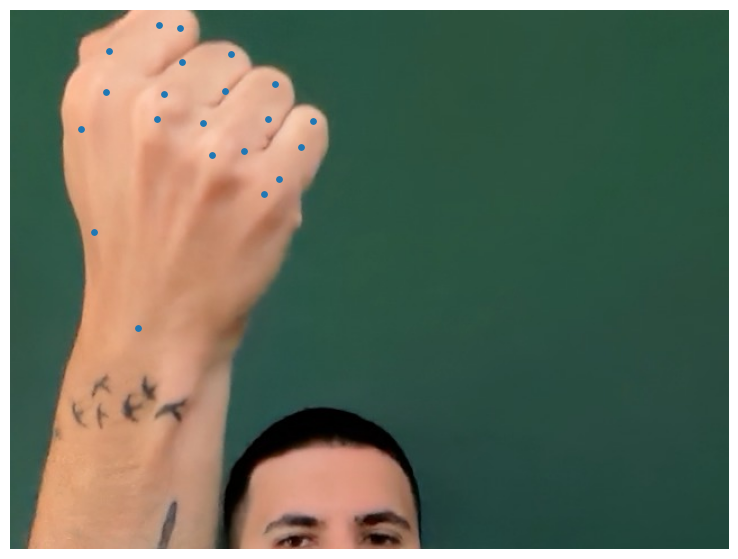

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
plt.imshow(rgb)

for hand in result.hand_landmarks:
    xs = [lm.x * frame.shape[1] for lm in hand]
    ys = [lm.y * frame.shape[0] for lm in hand]

    plt.scatter(xs, ys, s=15)

plt.axis("off")
plt.show()

capturare imagine maini.

In [10]:
frame = capture_frame()

rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb
)

result = detector.detect(mp_image)

hands_detected = len(result.hand_landmarks)

print("Mâini detectate:", hands_detected)
print("Landmarks detectate:", hands_detected * 21)

<IPython.core.display.Javascript object>

Mâini detectate: 2
Landmarks detectate: 42


AFISARE IMAGINE CU PUNCTELE DETECTATE PE MAINI.

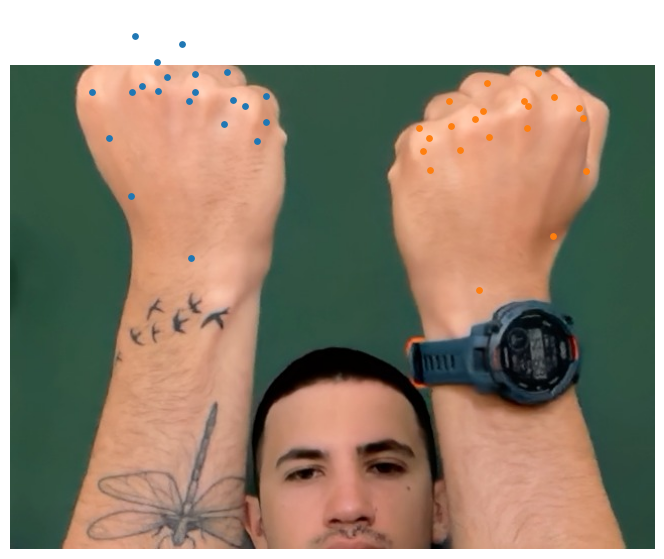

In [11]:
plt.figure(figsize=(10, 7))
plt.imshow(rgb)

for hand in result.hand_landmarks:
    xs = [lm.x * frame.shape[1] for lm in hand]
    ys = [lm.y * frame.shape[0] for lm in hand]
    plt.scatter(xs, ys, s=15)

plt.axis("off")
plt.show()

In [12]:
from google.colab import files

uploaded = files.upload()

video_path = next(iter(uploaded))
print("Video:", video_path)

Saving IMG_3885.MOV to IMG_3885.MOV
Video: IMG_3885.MOV


       MEDIAPIPE - VIDEO ANALYSIS
Total cadre analizate: 2411

NUMĂR MÂINI DETECTATE:
1 mână: 2155 cadre (89.38%)
2 mâini: 1 cadre (0.04%)
0 mâini: 255 cadre (10.58%)

INDICATORI DE DETECȚIE:
Cel puțin o mână: 89.42%
Ambele mâini: 0.04%
Fără detecție: 10.58%


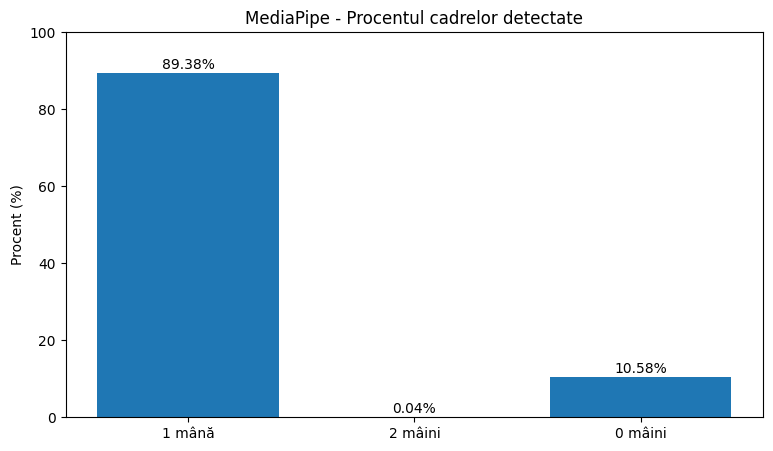

In [13]:
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

# Deschidem videoclipul
cap = cv2.VideoCapture(video_path)

# Inițializare statistici
total_frames = 0
both_hands_frames = 0
one_hand_frames = 0
no_hands_frames = 0

# Procesare videoclip
while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    total_frames += 1

    # Convertim imaginea BGR în RGB
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Pregătim imaginea pentru MediaPipe
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    # Detectăm mâinile
    result = detector.detect(mp_image)

    hands_detected = len(result.hand_landmarks)

    # Clasificăm cadrul
    if hands_detected >= 2:
        both_hands_frames += 1

    elif hands_detected == 1:
        one_hand_frames += 1

    else:
        no_hands_frames += 1

# Închidem videoclipul
cap.release()

# Calculăm procentele
at_least_one = (
    (one_hand_frames + both_hands_frames)
    / total_frames * 100 if total_frames else 0
)

both_hands_percentage = (
    both_hands_frames
    / total_frames * 100 if total_frames else 0
)

one_hand_percentage = (
    one_hand_frames
    / total_frames * 100 if total_frames else 0
)

no_hands_percentage = (
    no_hands_frames
    / total_frames * 100 if total_frames else 0
)

# Afișăm rezultatele
print("=" * 45)
print("       MEDIAPIPE - VIDEO ANALYSIS")
print("=" * 45)

print(f"Total cadre analizate: {total_frames}")

print("\nNUMĂR MÂINI DETECTATE:")

print(f"1 mână: {one_hand_frames} cadre ({one_hand_percentage:.2f}%)")
print(f"2 mâini: {both_hands_frames} cadre ({both_hands_percentage:.2f}%)")
print(f"0 mâini: {no_hands_frames} cadre ({no_hands_percentage:.2f}%)")

print("\nINDICATORI DE DETECȚIE:")

print(f"Cel puțin o mână: {at_least_one:.2f}%")
print(f"Ambele mâini: {both_hands_percentage:.2f}%")
print(f"Fără detecție: {no_hands_percentage:.2f}%")

print("=" * 45)

# Grafic rezultate
labels = ['1 mână', '2 mâini', '0 mâini']

values = [
    one_hand_percentage,
    both_hands_percentage,
    no_hands_percentage
]

plt.figure(figsize=(9, 5))
plt.bar(labels, values)

plt.title("MediaPipe - Procentul cadrelor detectate")
plt.ylabel("Procent (%)")
plt.ylim(0, 100)

for i, value in enumerate(values):
    plt.text(i, value + 1, f"{value:.2f}%", ha='center')

plt.show()

In [15]:
import cv2
import mediapipe as mp
from google.colab import files
from IPython.display import Video, display

# Conexiunile anatomice ale mâinii
HAND_CONNECTIONS = [
    (0,1),(1,2),(2,3),(3,4),
    (0,5),(5,6),(6,7),(7,8),
    (5,9),(9,10),(10,11),(11,12),
    (9,13),(13,14),(14,15),(15,16),
    (13,17),(17,18),(18,19),(19,20),
    (0,17)
]

# Deschidem videoclipul
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

output_path = "/content/hand_landmarks_output.mp4"

fourcc = cv2.VideoWriter_fourcc(*'mp4v')

out = cv2.VideoWriter(
    output_path,
    fourcc,
    fps,
    (width, height)
)

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    result = detector.detect(mp_image)

    for hand_landmarks in result.hand_landmarks:

        # Desenăm conexiunile
        for start_idx, end_idx in HAND_CONNECTIONS:

            start = hand_landmarks[start_idx]
            end = hand_landmarks[end_idx]

            x1 = int(start.x * width)
            y1 = int(start.y * height)

            x2 = int(end.x * width)
            y2 = int(end.y * height)

            cv2.line(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

        # Desenăm cele 21 de puncte
        for idx, landmark in enumerate(hand_landmarks):

            x = int(landmark.x * width)
            y = int(landmark.y * height)

            cv2.circle(
                frame,
                (x, y),
                5,
                (0, 0, 255),
                -1
            )

            cv2.putText(
                frame,
                str(idx),
                (x + 5, y - 5),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.4,
                (255, 255, 0),
                1
            )

    out.write(frame)

cap.release()
out.release()

print("Videoclip procesat cu succes!")
print("Salvat la:", output_path)

Videoclip procesat cu succes!
Salvat la: /content/hand_landmarks_output.mp4


In [17]:
!ffmpeg -y -i /content/hand_landmarks_output.mp4 \
-vcodec libx264 -pix_fmt yuv420p \
/content/hand_landmarks_final.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [18]:
from IPython.display import HTML, display
from base64 import b64encode

video_file = "/content/hand_landmarks_final.mp4"

with open(video_file, "rb") as f:
    video_data = b64encode(f.read()).decode()

display(HTML(f"""
<video width="720" controls>
    <source src="data:video/mp4;base64,{video_data}" type="video/mp4">
</video>
"""))

In [19]:
from google.colab import files
files.download(video_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import cv2
import mediapipe as mp
import pandas as pd
import numpy as np

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

data = []
frame_index = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    timestamp = frame_index / fps if fps > 0 else 0

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    result = detector.detect(mp_image)

    row = {
        "frame": frame_index,
        "timestamp": timestamp,
        "hands_detected": len(result.hand_landmarks)
    }

    # Extragem prima mână detectată
    if len(result.hand_landmarks) > 0:

        hand = result.hand_landmarks[0]

        for i, landmark in enumerate(hand):

            row[f"x_{i}"] = landmark.x
            row[f"y_{i}"] = landmark.y
            row[f"z_{i}"] = landmark.z

    else:

        for i in range(21):
            row[f"x_{i}"] = np.nan
            row[f"y_{i}"] = np.nan
            row[f"z_{i}"] = np.nan

    data.append(row)

    frame_index += 1

cap.release()

df = pd.DataFrame(data)

print("Feature extraction completed!")
print("Total frames:", len(df))
print("Dataset shape:", df.shape)

display(df.head())

Feature extraction completed!
Total frames: 2411
Dataset shape: (2411, 66)


,frame,timestamp,hands_detected,x_0,y_0,z_0,x_1,y_1,z_1,x_2,...,z_17,x_18,y_18,z_18,x_19,y_19,z_19,x_20,y_20,z_20
0,0,0.000000,1,-0.041811,0.967352,0.000002,0.093502,0.951715,-0.152173,0.235853,...,0.209607,0.200102,0.793103,0.223852,0.284936,0.817051,0.205189,0.337377,0.848204,0.192452
1,1,0.033361,1,-0.024296,0.965852,0.000002,0.099949,0.949146,-0.164760,0.239456,...,0.207426,0.221457,0.791116,0.212735,0.291515,0.819890,0.188441,0.325806,0.853018,0.173825
2,2,0.066722,1,-0.025013,0.965715,0.000002,0.089387,0.952082,-0.166359,0.226440,...,0.204362,0.224516,0.786167,0.211745,0.299136,0.811262,0.188790,0.337346,0.843335,0.174089
3,3,0.100083,1,-0.042610,0.964832,0.000002,0.085699,0.952892,-0.151454,0.226442,...,0.190332,0.207726,0.786489,0.197966,0.291755,0.810758,0.177543,0.339115,0.843153,0.165425
4,4,0.133444,1,-0.037688,0.967942,0.000002,0.093636,0.954285,-0.163023,0.228197,...,0.187529,0.214925,0.786594,0.184241,0.291588,0.813091,0.159157,0.331052,0.845312,0.145191


In [21]:
csv_path = "/content/hand_landmarks_dataset.csv"

df.to_csv(csv_path, index=False)

print("Dataset saved:", csv_path)

Dataset saved: /content/hand_landmarks_dataset.csv


In [22]:
from google.colab import files

files.download(csv_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

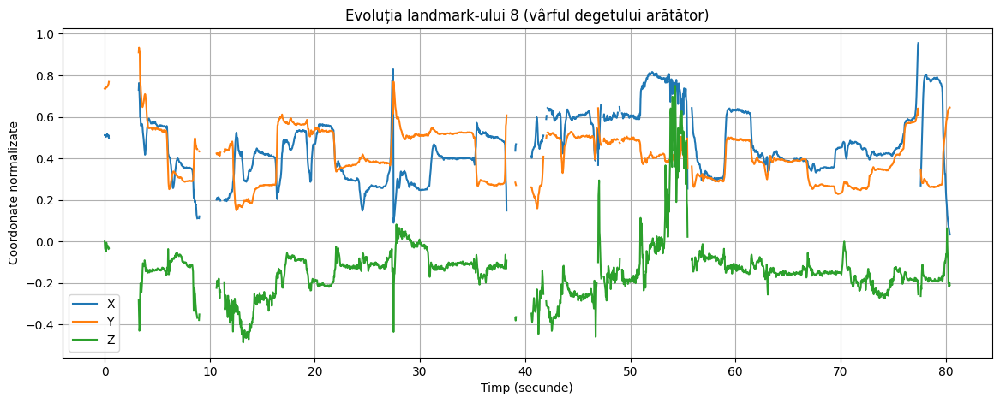

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["x_8"], label="X")
plt.plot(df["timestamp"], df["y_8"], label="Y")
plt.plot(df["timestamp"], df["z_8"], label="Z")

plt.title("Evoluția landmark-ului 8 (vârful degetului arătător)")
plt.xlabel("Timp (secunde)")
plt.ylabel("Coordonate normalizate")

plt.legend()
plt.grid()
plt.show()

In [1]:
import os

PROJECT_DIR = "/content/LSR_Project"

folders = [
    "videos",
    "metadata",
    "features",
    "models",
    "results"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project structure created:")
for folder in folders:
    print(f"  [OK] {folder}")

Project structure created:
  [OK] videos
  [OK] metadata
  [OK] features
  [OK] models
  [OK] results


In [2]:
!wget -c https://download.microsoft.com/download/b/8/8/b88c0bae-e6c1-43e1-8726-98cf5af36ca4/ASL_Citizen.zip -O /content/ASL_Citizen.zip

--2026-11-01 11:34:52--  https://download.microsoft.com/download/b/8/8/b88c0bae-e6c1-43e1-8726-98cf5af36ca4/ASL_Citizen.zip
Resolving download.microsoft.com (download.microsoft.com)... 23.217.125.182, 2600:1408:c400:168a::317f, 2600:1408:c400:1680::317f
Connecting to download.microsoft.com (download.microsoft.com)|23.217.125.182|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 45924134223 (43G) [application/octet-stream]
Saving to: ‘/content/ASL_Citizen.zip’

/content/ASL_Citize 100%[===================>]  42.77G  45.8MB/s    in 13m 24s 

2026-11-01 11:48:17 (54.4 MB/s) - ‘/content/ASL_Citizen.zip’ saved [45924134223/45924134223]



In [3]:
import zipfile
import os

zip_path = "/content/ASL_Citizen.zip"

print("File exists:", os.path.exists(zip_path))
print("File size (GB):", round(os.path.getsize(zip_path) / 1e9, 2))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Number of files:", len(z.namelist()))
    print("\nFirst 20 files:")
    for name in z.namelist()[:20]:
        print(name)

File exists: True
File size (GB): 45.92
Number of files: 83406

First 20 files:
ASL_Citizen/
ASL_Citizen/splits/
ASL_Citizen/splits/val.csv
ASL_Citizen/splits/train.csv
ASL_Citizen/splits/test.csv
ASL_Citizen/videos/
ASL_Citizen/videos/5086723486875651-RUN.mp4
ASL_Citizen/videos/2233415645150214-SWEET.mp4
ASL_Citizen/videos/09412352698319548-POSSIBLE.mp4
ASL_Citizen/videos/6184880487426632-PAINT.mp4
ASL_Citizen/videos/6682045893304822-RACE.mp4
ASL_Citizen/videos/22425009794174322-SCULPT.mp4
ASL_Citizen/videos/8563900568328626-SCAR MEMORY.mp4
ASL_Citizen/videos/6843553981288921-EARTHQUAKE.mp4
ASL_Citizen/videos/37687322393253075-REPLACE.mp4
ASL_Citizen/videos/8136380896447564-WRISTWATCH 3.mp4
ASL_Citizen/videos/023749434963018734-WHISTLE.mp4
ASL_Citizen/videos/639898672430512-PARTY 2.mp4
ASL_Citizen/videos/2743155783934501-ELEGANCE.mp4
ASL_Citizen/videos/11137281856386338-MENTION.mp4


In [4]:
import zipfile
import os

zip_path = "/content/ASL_Citizen.zip"
extract_dir = "/content/ASL_Citizen"

with zipfile.ZipFile(zip_path, "r") as z:
    for filename in [
        "ASL_Citizen/splits/train.csv",
        "ASL_Citizen/splits/val.csv",
        "ASL_Citizen/splits/test.csv"
    ]:
        z.extract(filename, "/content")

print("CSV files extracted successfully!")

CSV files extracted successfully!


In [5]:
import pandas as pd

train_df = pd.read_csv(
    "/content/ASL_Citizen/splits/train.csv"
)

val_df = pd.read_csv(
    "/content/ASL_Citizen/splits/val.csv"
)

test_df = pd.read_csv(
    "/content/ASL_Citizen/splits/test.csv"
)

print("TRAIN:", train_df.shape)
print("VALIDATION:", val_df.shape)
print("TEST:", test_df.shape)

print("\nCOLUMNS:")
print(train_df.columns.tolist())

print("\nFIRST 10 ROWS:")
display(train_df.head(10))

TRAIN: (40154, 4)
VALIDATION: (10304, 4)
TEST: (32941, 4)

COLUMNS:
['Participant ID', 'Video file', 'Gloss', 'ASL-LEX Code']

FIRST 10 ROWS:


,Participant ID,Video file,Gloss,ASL-LEX Code
0,P1,15890366051589533-APPLE.mp4,APPLE,A_03_054
1,P1,35618482303951104-IMPOSSIBLE.mp4,IMPOSSIBLE,B_01_032
2,P1,6958143575951994-PARK.mp4,PARK,E_03_028
3,P1,8006032738002744-SOCCER 2.mp4,SOCCER2,F_03_032
4,P1,37542279833186454-STINK.mp4,STINK,H_01_064
5,P1,9498964909837952-ROSE.mp4,ROSE,G_03_024
6,P1,9618808117704574-HUG.mp4,HUG,G_02_036
7,P1,15543213389651633-TUBE.mp4,TUBE,G_03_042
8,P1,9162908944303221-COUNT.mp4,COUNT,G_02_054
9,P1,14154575310664197-NICE.mp4,NICE,G_03_059


In [6]:
print("COLUMN ANALYSIS")

for col in train_df.columns:
    print(
        f"{col}: "
        f"{train_df[col].nunique()} unique values | "
        f"{train_df[col].isna().sum()} missing"
    )

print("\nPOSSIBLE LABEL DISTRIBUTIONS")

for col in train_df.select_dtypes(include="object").columns:
    if train_df[col].nunique() < 10000:
        print(f"\n--- {col} ---")
        display(train_df[col].value_counts().head(20))

COLUMN ANALYSIS
Participant ID: 35 unique values | 0 missing
Video file: 40154 unique values | 0 missing
Gloss: 2731 unique values | 0 missing
ASL-LEX Code: 2722 unique values | 88 missing

POSSIBLE LABEL DISTRIBUTIONS

--- Participant ID ---


,count
Participant ID,
P33,3000
P11,3000
P27,2999
P40,2998
P50,2991
P37,2989
P31,2971
P29,2933
P52,2728



--- Gloss ---


,count
Gloss,
DOG1,24
HURDLE/TRIP1,22
BREAKFAST1,21
DEMAND1,21
DARK1,21
BITE1,21
WHATFOR1,20
DEAF1,20
MECHANIC1,20



--- ASL-LEX Code ---


,count
ASL-LEX Code,
C_02_054,43
B_03_084,29
A_01_056,24
G_01_036,22
K_02_045,21
J_03_094,21
J_01_053,21
D_03_080,21
G_01_010,20


In [7]:
import pandas as pd

# Verificăm distribuția claselor
gloss_counts = train_df["Gloss"].value_counts()

# Selectăm primele 20 de clase
selected_glosses = gloss_counts.head(20).index.tolist()

print("Selected classes:", len(selected_glosses))

display(
    gloss_counts.head(20).reset_index()
    .rename(columns={"index": "Gloss", "count": "Samples"})
)

Selected classes: 20


,Gloss,Samples
0,DOG1,24
1,HURDLE/TRIP1,22
2,BREAKFAST1,21
3,DEMAND1,21
4,DARK1,21
5,BITE1,21
6,WHATFOR1,20
7,DEAF1,20
8,MECHANIC1,20
9,PARTY1,20


In [8]:
for name, dataset in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    filtered = dataset[dataset["Gloss"].isin(selected_glosses)]

    print(f"\n{name}")
    print("Total samples:", len(filtered))
    print("Unique classes:", filtered["Gloss"].nunique())

    print(filtered["Gloss"].value_counts().sort_index())


TRAIN
Total samples: 402
Unique classes: 20
Gloss
BASKETBALL1      19
BEE1             19
BELT1            19
BITE1            21
BREAKFAST1       21
DARK1            21
DEAF1            20
DECIDE1          20
DEMAND1          21
DEVELOP1         19
DOG1             24
EDIT1            19
ELEVATOR1        19
HURDLE/TRIP1     22
LUNCH1           19
MECHANIC1        20
PARTY1           20
PATIENT2         19
ROCKINGCHAIR1    20
WHATFOR1         20
Name: count, dtype: int64

VALIDATION
Total samples: 79
Unique classes: 20
Gloss
BASKETBALL1      5
BEE1             6
BELT1            3
BITE1            4
BREAKFAST1       3
DARK1            3
DEAF1            4
DECIDE1          3
DEMAND1          4
DEVELOP1         3
DOG1             4
EDIT1            4
ELEVATOR1        5
HURDLE/TRIP1     3
LUNCH1           5
MECHANIC1        3
PARTY1           4
PATIENT2         4
ROCKINGCHAIR1    4
WHATFOR1         5
Name: count, dtype: int64

TEST
Total samples: 308
Unique classes: 20
Gloss
BASKETBALL1 

In [9]:
import zipfile
import os

zip_path = "/content/ASL_Citizen.zip"
output_dir = "/content/LSR_Project/videos"

os.makedirs(output_dir, exist_ok=True)

selected_files = set()

for dataset in [train_df, val_df, test_df]:
    filtered = dataset[dataset["Gloss"].isin(selected_glosses)]
    selected_files.update(filtered["Video file"].tolist())

print("Videos to extract:", len(selected_files))

extracted = 0
missing = []

with zipfile.ZipFile(zip_path, "r") as z:
    for filename in selected_files:

        archive_path = f"ASL_Citizen/videos/{filename}"

        try:
            info = z.getinfo(archive_path)
            destination = os.path.join(output_dir, filename)

            if not os.path.exists(destination):
                with z.open(info) as source, open(destination, "wb") as target:
                    target.write(source.read())

            extracted += 1

        except KeyError:
            missing.append(filename)

print("Extracted:", extracted)
print("Missing:", len(missing))

Videos to extract: 789
Extracted: 789
Missing: 0


In [10]:
metadata_dir = "/content/LSR_Project/metadata"

os.makedirs(metadata_dir, exist_ok=True)

for name, dataset in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    filtered = dataset[
        dataset["Gloss"].isin(selected_glosses)
    ].copy()

    filtered.to_csv(
        f"{metadata_dir}/{name}.csv",
        index=False
    )

print("Metadata saved successfully!")

Metadata saved successfully!


In [11]:
for name in ["train", "validation", "test"]:
    df_check = pd.read_csv(
        f"/content/LSR_Project/metadata/{name}.csv"
    )

    print(f"\n{name.upper()}")
    print("Samples:", len(df_check))
    print("Classes:", df_check["Gloss"].nunique())

    display(
        df_check["Gloss"]
        .value_counts()
        .sort_values(ascending=False)
    )


TRAIN
Samples: 402
Classes: 20


,count
Gloss,
DOG1,24
HURDLE/TRIP1,22
DARK1,21
BREAKFAST1,21
DEMAND1,21
BITE1,21
PARTY1,20
WHATFOR1,20
DEAF1,20



VALIDATION
Samples: 79
Classes: 20


,count
Gloss,
BEE1,6
WHATFOR1,5
BASKETBALL1,5
LUNCH1,5
ELEVATOR1,5
DOG1,4
PATIENT2,4
DEMAND1,4
DEAF1,4



TEST
Samples: 308
Classes: 20


,count
Gloss,
BASKETBALL1,20
WHATFOR1,18
BELT1,18
DOG1,17
PATIENT2,16
MECHANIC1,16
ELEVATOR1,15
DECIDE1,15
PARTY1,15


In [12]:
import os

video_dir = "/content/LSR_Project/videos"

videos = [
    f for f in os.listdir(video_dir)
    if f.lower().endswith(".mp4")
]

print("Extracted videos:", len(videos))
print("Expected videos:", len(selected_files))
print("Missing videos:", len(missing))

Extracted videos: 789
Expected videos: 789
Missing videos: 0


In [22]:

import numpy as np
import cv2
import mediapipe as mp

SEQUENCE_LENGTH = 30
FEATURES_PER_FRAME = 126

def extract_hand_features(video_path):
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames == 0:
        cap.release()
        return None

    frame_indices = np.linspace(
        0, total_frames - 1, SEQUENCE_LENGTH
    ).astype(int)

    sequence = []

    for frame_idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        ret, frame = cap.read()

        features = np.zeros(FEATURES_PER_FRAME, dtype=np.float32)

        if ret:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            result = detector.detect(mp_image)

            if result.hand_landmarks:
                for i, hand in enumerate(result.hand_landmarks):
                    if i >= 2:
                        break

                    handedness = result.handedness[i][0].category_name
                    hand_index = 0 if handedness == "Left" else 1
                    offset = hand_index * 63

                    for j, landmark in enumerate(hand):
                        features[offset + j * 3] = landmark.x
                        features[offset + j * 3 + 1] = landmark.y
                        features[offset + j * 3 + 2] = landmark.z

        sequence.append(features)

    cap.release()

    return np.array(sequence, dtype=np.float32)

In [25]:
!wget -q https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task -O /content/hand_landmarker.task

In [26]:
import mediapipe as mp

BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = HandLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path="/content/hand_landmarker.task"
    ),
    running_mode=RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5,
    min_tracking_confidence=0.5
)

detector = HandLandmarker.create_from_options(options)

print("MediaPipe detector inițializat!")

MediaPipe detector inițializat!


In [27]:
sample_features = extract_hand_features(sample_video)

print("Shape:", sample_features.shape)
print("NaN:", np.isnan(sample_features).sum())
print("Valori nenule:", np.count_nonzero(sample_features))

Shape: (30, 126)
NaN: 0
Valori nenule: 945


In [28]:
import os
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

project_dir = "/content/LSR_Project"
video_dir = os.path.join(project_dir, "videos")
features_dir = os.path.join(project_dir, "features")

os.makedirs(features_dir, exist_ok=True)

splits = {
    "train": os.path.join(project_dir, "metadata", "train.csv"),
    "validation": os.path.join(project_dir, "metadata", "validation.csv"),
    "test": os.path.join(project_dir, "metadata", "test.csv")
}

for split_name, csv_path in splits.items():

    df = pd.read_csv(csv_path)
    output_dir = os.path.join(features_dir, split_name)
    os.makedirs(output_dir, exist_ok=True)

    successful = 0
    failed = 0

    print(f"\nProcesare {split_name}: {len(df)} videoclipuri")

    for _, row in tqdm(df.iterrows(), total=len(df), desc=split_name):

        filename = row["Video file"]
        video_path = os.path.join(video_dir, filename)

        output_name = os.path.splitext(filename)[0] + ".npy"
        output_path = os.path.join(output_dir, output_name)

        if os.path.exists(output_path):
            successful += 1
            continue

        try:
            features = extract_hand_features(video_path)

            if features is None or features.shape != (30, 126):
                failed += 1
                continue

            np.save(output_path, features)
            successful += 1

        except Exception as e:
            failed += 1
            print(f"\nEroare la {filename}: {e}")

    print(f"\n{split_name.upper()} – finalizat")
    print("Salvate:", successful)
    print("Eșuate:", failed)

print("\nProcesarea tuturor seturilor s-a încheiat.")


Procesare train: 402 videoclipuri


train:   0%|          | 0/402 [00:00<?, ?it/s]


TRAIN – finalizat
Salvate: 402
Eșuate: 0

Procesare validation: 79 videoclipuri


validation:   0%|          | 0/79 [00:00<?, ?it/s]


VALIDATION – finalizat
Salvate: 79
Eșuate: 0

Procesare test: 308 videoclipuri


test:   0%|          | 0/308 [00:00<?, ?it/s]


TEST – finalizat
Salvate: 308
Eșuate: 0

Procesarea tuturor seturilor s-a încheiat.


In [29]:
for split_name in ["train", "validation", "test"]:
    folder = os.path.join(features_dir, split_name)
    files = [f for f in os.listdir(folder) if f.endswith(".npy")]
    print(split_name.upper(), ":", len(files), "secvențe")

TRAIN : 402 secvențe
VALIDATION : 79 secvențe
TEST : 308 secvențe
